# Libraries

In [21]:
%pip install numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
%pip install sklearn

  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [26]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

In [29]:
file_path = "D:\\ict_task\\CASE15\\WA_Fn-UseC_-Telco-Customer-Churn (1).csv"

# EDA

In [30]:
df = pd.read_csv(file_path)

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [32]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [33]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [34]:
df.shape

(7043, 21)

In [35]:
df.value_counts().sum()

np.int64(7043)

In [36]:
df.duplicated().sum()

np.int64(0)

In [37]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [38]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

# Data Visualization

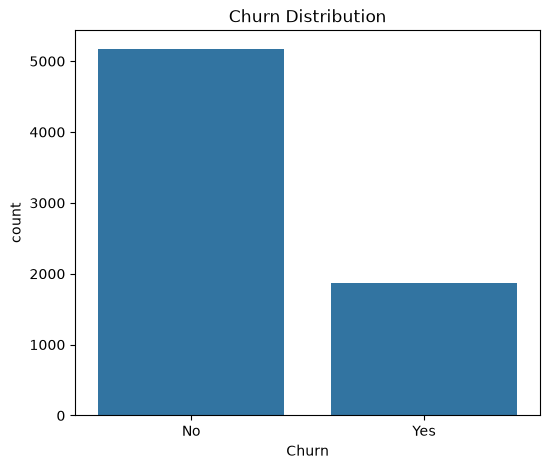

In [39]:
# Target distribution plot for checking class imbalance visually

plt.figure(figsize=(6, 5))
sns.countplot(df, x="Churn")
plt.title("Churn Distribution")
plt.show()

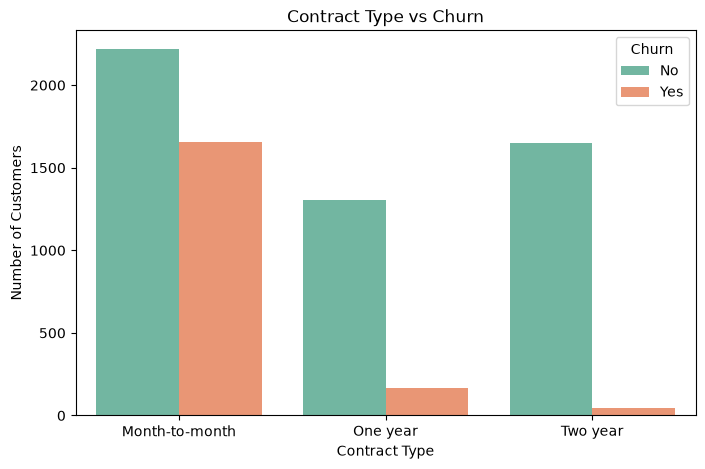

In [40]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set2')
plt.title("Contract Type vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

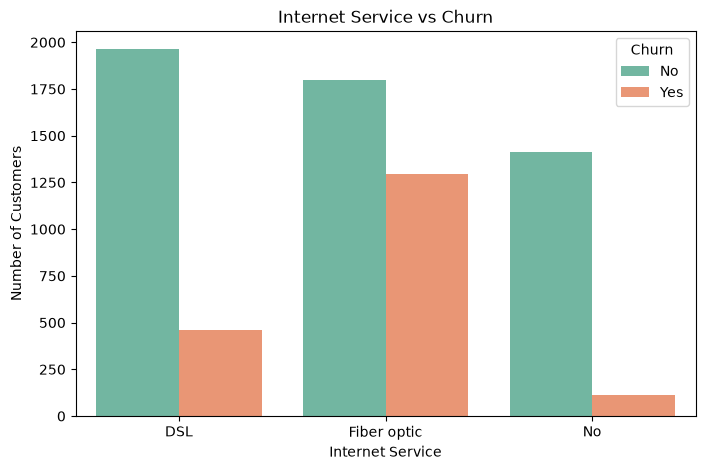

In [41]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='InternetService', hue='Churn', palette='Set2')
plt.title("Internet Service vs Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

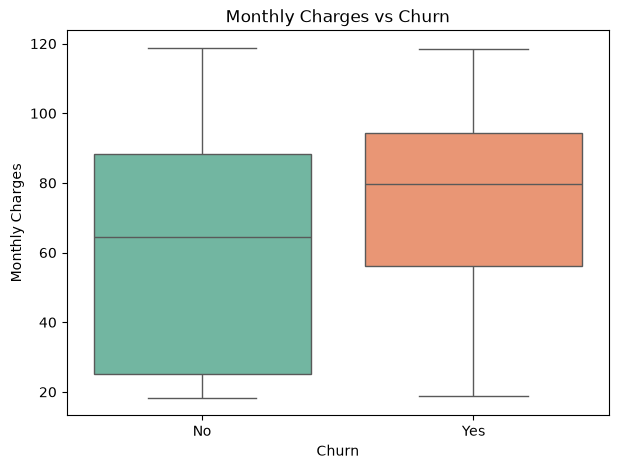

In [42]:
plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette='Set2', legend=False)
plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

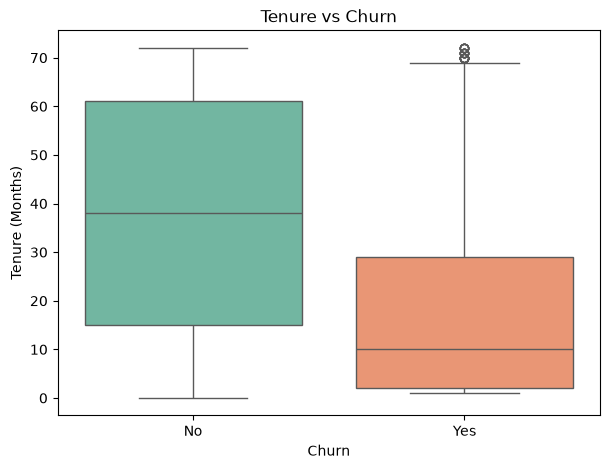

In [43]:
plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='Churn', y='tenure', hue='Churn', palette='Set2', legend=False)
plt.title("Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

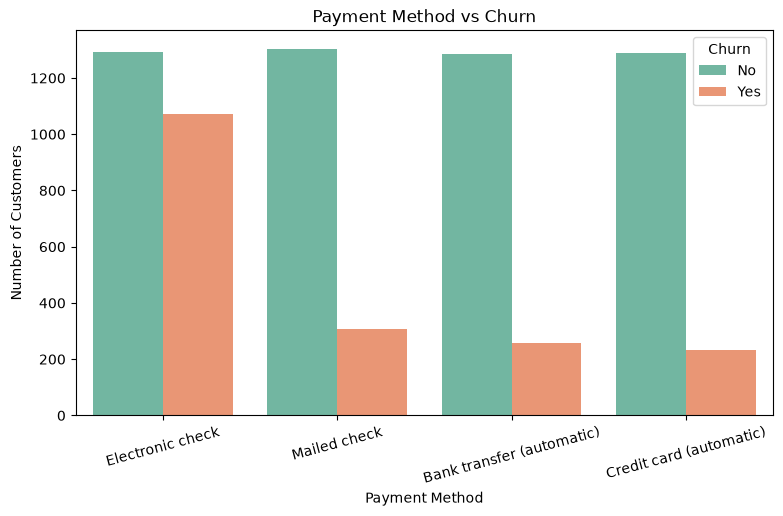

In [44]:
plt.figure(figsize=(9,5))
sns.countplot(data=df, x='PaymentMethod', hue='Churn', palette='Set2')
plt.title("Payment Method vs Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

# Data Cleaning

In [45]:
df = df.drop(columns = "customerID")

In [46]:
print(df['TotalCharges'].unique())
print(df['TotalCharges'].dtype)

<StringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95',
 ...
 '2625.25', '6886.25',  '1495.1',   '743.3',  '1419.4',  '1990.5',  '7362.9',
  '346.45',   '306.6',  '6844.5']
Length: 6531, dtype: str
str


In [47]:
# TotalCharges is stored as object because some values contain blank spaces.
df['TotalCharges'].str.strip().eq('').sum()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')

In [48]:
print(df['TotalCharges'].dtype)

float64


In [49]:
df.isnull().sum()/ len(df)*100

gender              0.000000
SeniorCitizen       0.000000
Partner             0.000000
Dependents          0.000000
tenure              0.000000
PhoneService        0.000000
MultipleLines       0.000000
InternetService     0.000000
OnlineSecurity      0.000000
OnlineBackup        0.000000
DeviceProtection    0.000000
TechSupport         0.000000
StreamingTV         0.000000
StreamingMovies     0.000000
Contract            0.000000
PaperlessBilling    0.000000
PaymentMethod       0.000000
MonthlyCharges      0.000000
TotalCharges        0.156183
Churn               0.000000
dtype: float64

In [50]:
df.dropna(subset=['TotalCharges'], inplace=True)

C:\Users\Devika N S\AppData\Local\Temp\ipykernel_11716\2498762546.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['TotalCharges'], inplace=True)


In [51]:
df.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [52]:
cat_cols_before_split = df.select_dtypes(exclude="number")

for col in cat_cols_before_split:
  print(f"{col} ---> {df[col].unique()}")
  print(" ")

gender ---> <StringArray>
['Female', 'Male']
Length: 2, dtype: str
 
Partner ---> <StringArray>
['Yes', 'No']
Length: 2, dtype: str
 
Dependents ---> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
 
PhoneService ---> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
 
MultipleLines ---> <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
 
InternetService ---> <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
 
OnlineSecurity ---> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
 
OnlineBackup ---> <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
 
DeviceProtection ---> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
 
TechSupport ---> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
 
StreamingTV ---> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
 
StreamingMovies ---> <StringArray>
['No', 'Yes', 'No internet service']
Length: 

In [53]:
X = df.drop(columns="Churn")
y = df["Churn"]

# Separate test data
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Separate training and validation data
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (4218, 19)
Validation data: (1407, 19)
Testing data: (1407, 19)


In [54]:
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

# Scaling

In [55]:
scaler = StandardScaler()

# Scale the actual numeric data from X_train and X_test using the num_cols index
X_train_num_scaled = scaler.fit_transform(X_train[num_cols])
X_test_num_scaled = scaler.transform(X_test[num_cols])

In [56]:
X_train_num_scaled = pd.DataFrame(X_train_num_scaled, columns=num_cols, index=X_train.index)
X_test_num_scaled = pd.DataFrame(X_test_num_scaled, columns=num_cols, index=X_test.index)


X_train_cat = pd.DataFrame(X_train[cat_cols], columns=cat_cols, index=X_train.index)
X_test_cat = pd.DataFrame(X_test[cat_cols], columns=cat_cols, index=X_test.index)

# Encoding

In [57]:
for col in cat_cols:
  print(f"{col} ---->  {X_train_cat[col].unique()}")
  print(" ")

gender ---->  <StringArray>
['Female', 'Male']
Length: 2, dtype: str
 
Partner ---->  <StringArray>
['Yes', 'No']
Length: 2, dtype: str
 
Dependents ---->  <StringArray>
['Yes', 'No']
Length: 2, dtype: str
 
PhoneService ---->  <StringArray>
['Yes', 'No']
Length: 2, dtype: str
 
MultipleLines ---->  <StringArray>
['Yes', 'No', 'No phone service']
Length: 3, dtype: str
 
InternetService ---->  <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
 
OnlineSecurity ---->  <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
 
OnlineBackup ---->  <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
 
DeviceProtection ---->  <StringArray>
['No', 'No internet service', 'Yes']
Length: 3, dtype: str
 
TechSupport ---->  <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
 
StreamingTV ---->  <StringArray>
['No', 'No internet service', 'Yes']
Length: 3, dtype: str
 
StreamingMovies ---->  <StringArray>
['No', 'No internet s

In [58]:
ord_enc = OrdinalEncoder(
    categories=[['Month-to-month', 'One year', 'Two year']]
)

ord_train = pd.DataFrame(
    ord_enc.fit_transform(X_train_cat[['Contract']]),
    columns=['Contract'],
    index=X_train.index
)

ord_test = pd.DataFrame(
    ord_enc.transform(X_test_cat[['Contract']]),
    columns=['Contract'],
    index=X_test.index
)

In [59]:
oh_cols = [
    "gender", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "PaperlessBilling",
    "PaymentMethod"
]

oh_enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

oh_train = pd.DataFrame(
    oh_enc.fit_transform(X_train_cat[oh_cols]),
    columns=oh_enc.get_feature_names_out(oh_cols),
    index=X_train.index
)

oh_test = pd.DataFrame(
    oh_enc.transform(X_test_cat[oh_cols]),
    columns=oh_enc.get_feature_names_out(oh_cols),
    index=X_test.index
)

In [60]:
X_train_final = pd.concat([X_train_num_scaled, ord_train, oh_train], axis=1)
X_test_final = pd.concat([X_test_num_scaled, ord_test, oh_test], axis=1)

print(X_train_final.shape, X_test_final.shape)
X_train_final.head()


(4218, 43) (1407, 43)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Contract,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
1646,-0.439557,1.086285,0.015215,0.675299,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2735,2.275015,0.800390,0.264604,0.687936,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
6476,-0.439557,0.841233,-0.029976,0.537711,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2588,-0.439557,-0.996661,-0.523733,-0.831859,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4667,-0.439557,-0.506556,-1.533005,-0.846517,0.0,1.0,0.0,0.0,1.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [61]:
print(X_train_final.isnull().sum().sum())
print(X_test_final.isnull().sum().sum())

0
0


In [62]:
y_train = y_train.map({'No': 0, 'Yes': 1})
y_test = y_test.map({'No': 0, 'Yes': 1})

In [63]:
print(y_test.value_counts())
print(y_test.isnull().sum())

Churn
0    1033
1     374
Name: count, dtype: int64
0


# Class Imbalance

In [64]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_final, y_train)

print(y_train_smote.value_counts())

Churn
0    3097
1    3097
Name: count, dtype: int64


# Feature Selection

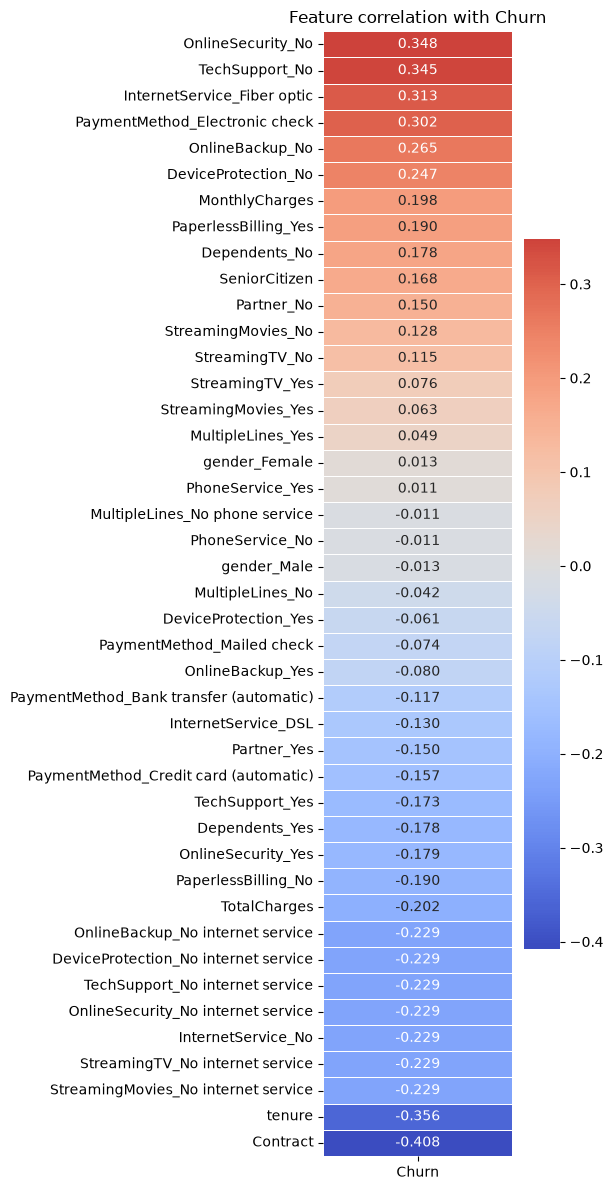

In [65]:
corr = X_train_final.corrwith(y_train).sort_values(ascending=False).to_frame("Churn")

plt.figure(figsize=(6, 12))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5,
    center=0
)
plt.title("Feature correlation with Churn")
plt.tight_layout()
plt.show()

In [66]:
features_selected = ['Contract','tenure','OnlineBackup_No',]
X_train_selected = X_train_smote[features_selected]
X_test_selected = X_test_final[features_selected]

# Logistic Regression

In [67]:
log_reg = LogisticRegression()
knn = KNeighborsClassifier(n_neighbors = 3)

In [68]:
log_reg.fit(X_train_selected, y_train_smote)
knn.fit(X_train_selected, y_train_smote)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [69]:
#Predict the target labels for the training set using the trained Logistic Regression model
lr_train_pred = log_reg.predict(X_train_selected)
# Predict the target labels for the test set using the trained Logistic Regression model
lr_test_pred = log_reg.predict(X_test_selected)

In [70]:
#Predict the target labels for the training set using the trained (KNN)
knn_train_pred = knn.predict(X_train_selected)
# Predict the target labels for the test set using the trained (KNN)
knn_test_pred = knn.predict(X_test_selected)

# Accuracy Score

In [71]:
#Accuracy Score
# Calculate accuracy on train set
lr_train_acc = accuracy_score(y_train_smote, lr_train_pred)

# Calculate accuracy on test set
lr_test_acc = accuracy_score(y_test, lr_test_pred)

In [72]:
# Print the training accuracy of the logistic Regression model
print(f" Logistic Regression Train Accuracy : {lr_train_acc:.4f}")

# Print the testing accuracy of the Logistic Regression Model
print(f" Logistic Regression Test Accuracy : {lr_test_acc:.4f}")

 Logistic Regression Train Accuracy : 0.7410
 Logistic Regression Test Accuracy : 0.6617


# KNN

In [73]:
#KNN Score
# Calculate KNN on train set
knn_train_acc = accuracy_score(y_train_smote, knn_train_pred)

# Calculate KNN on test set
knn_test_acc = accuracy_score(y_test, knn_test_pred)

In [74]:
# Print the training accuracy of KNN
print(f" KNN Train Accuracy : {knn_train_acc:.4f}")

# Print the testing accuracy of KNN
print(f" KNN Test Accuracy : {knn_test_acc:.4f}")

 KNN Train Accuracy : 0.8063
 KNN Test Accuracy : 0.7200


# Confusion Matrix

In [75]:
# Calculate the confusion matrix for the Logistic Regression model on the test set
lr_cm = confusion_matrix(y_test, lr_test_pred)

#Print the confusion matrix to visualize model performance
print("Confusion Matrix: ")
print(lr_cm)


Confusion Matrix: 
[[615 418]
 [ 58 316]]


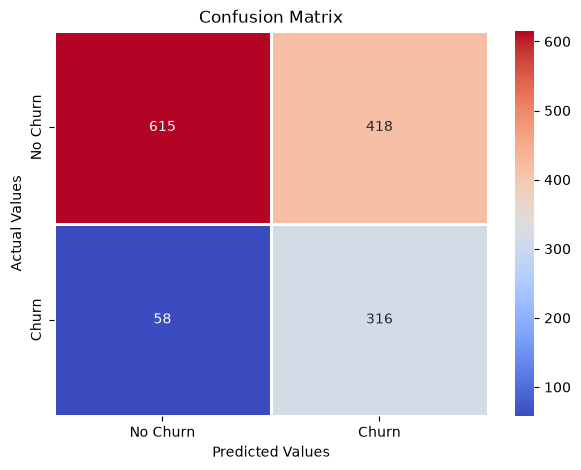

In [76]:
#HEAT MAP
plt.figure(figsize=(7,5))
sns.heatmap(
    lr_cm,
    annot=True,
    fmt='d',
    cmap='coolwarm',
    linewidths=1,
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

# Classification Report

In [77]:
#Generates a classification report for the Logistic Regression model on the test set

log_cr = classification_report(y_test, lr_test_pred)

#Print the classification report to evaluate model performance in detail
print("Classification Report:")
print(log_cr)

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.60      0.72      1033
           1       0.43      0.84      0.57       374

    accuracy                           0.66      1407
   macro avg       0.67      0.72      0.65      1407
weighted avg       0.79      0.66      0.68      1407

